# 02. Baseline CNN

The scratch CNN trains for 30 epochs with Adam (lr 1e-3, cosine schedule), batch 128 and seed 42. It uses random crop and flip on the 45,000 training images. The 5,000 validation images pick the best epoch.

In [1]:
import os

os.chdir("..")  # run from the repo root so paths match the scripts
import matplotlib.pyplot as plt
from src.utils import FIG_DIR, load_runs

run = load_runs("baseline")[0]
h = run["history"]
print(run["run_id"])
print(f"best val acc {run['best_val_acc']:.4f} at epoch {run['best_epoch']}, {run['params']:,} parameters, {run['train_time_s'] / 60:.1f} min")
print(f"final train acc {h['train_acc'][-1]:.4f}, val acc {h['val_acc'][-1]:.4f}, gap {100 * (h['train_acc'][-1] - h['val_acc'][-1]):.1f} points")

scratch_adam_lr0.001_bs128_cosine_e30_s42
best val acc 0.8720 at epoch 30, 1,672,010 parameters, 33.2 min
final train acc 0.7924, val acc 0.8720, gap -8.0 points


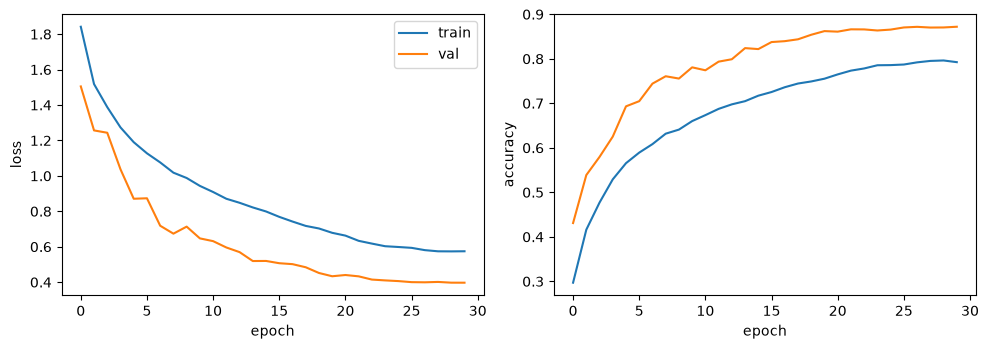

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(h["train_loss"], label="train")
axes[0].plot(h["val_loss"], label="val")
axes[0].set(xlabel="epoch", ylabel="loss")
axes[1].plot(h["train_acc"], label="train")
axes[1].plot(h["val_acc"], label="val")
axes[1].set(xlabel="epoch", ylabel="accuracy")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "baseline_curves.png", dpi=120)

The baseline reaches 87.2% val accuracy at epoch 30 and clears the 82% bar for Phase 2. Train accuracy (79.2%) sits below val accuracy because it is measured with dropout and augmentation switched on. The train-val gap is negative, so the model needs no extra dropout or weight decay. Val accuracy still rose at the last epoch, so more epochs would help. The plan fixes 30 epochs, and later phases keep that budget.